1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


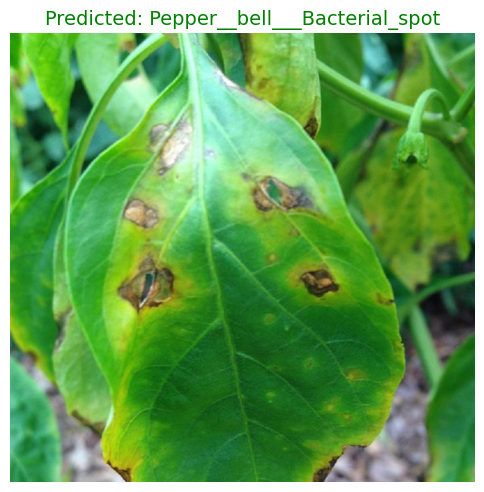

In [21]:
import tensorflow as tf
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt

# ---------------------- MODEL & PATHS ----------------------
MODEL_PATH = r"mobilenetv2_kfold_outputs\mobilenetv2_fold2_20251014_191351.keras"
DATASET_DIR = r"C:\Users\natra\Downloads\dl project dataset\PlantVillage"
IMAGE_PATH = r"C:\Users\natra\Downloads\hgic_veg_bacterial leaf spot_pepper_800.jpg" 

# ---------------------- LOAD MODEL ----------------------
model = tf.keras.models.load_model(MODEL_PATH)

# Get class names in sorted order (same as during training)
classes = sorted([d for d in os.listdir(DATASET_DIR) if os.path.isdir(os.path.join(DATASET_DIR, d))])

# ---------------------- IMAGE PREPROCESSING ----------------------
def preprocess_image(img_path, target_size=(224, 224)):
    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img_rgb, target_size)
    img_norm = img_resized.astype("float32") / 255.0
    img_expanded = np.expand_dims(img_norm, axis=0)
    return img_rgb, img_expanded

# Preprocess the image
img_rgb, img_input = preprocess_image(IMAGE_PATH)

# ---------------------- PREDICTION ----------------------
pred = model.predict(img_input)
pred_class = classes[np.argmax(pred)]

# ---------------------- DISPLAY ----------------------
plt.figure(figsize=(6, 6))
plt.imshow(img_rgb)
plt.axis("off")
plt.title(f"Predicted: {pred_class}", fontsize=14, color="green")
plt.show()

